In [92]:
import os
import sys

project_root = os.path.abspath(os.path.join(os.getcwd(), ".."))
if project_root not in sys.path:
    sys.path.append(project_root)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio

pio.templates.default = "plotly_white"
pio.renderers.default = "vscode+png"

from src.database import engine
import kaleido

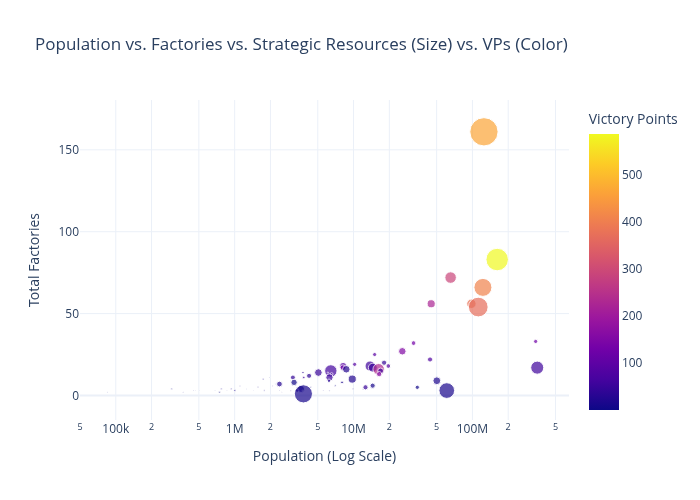

In [93]:
query = """
SELECT 
    c.country_name,
    c.country_tag,
    COUNT(s.state_id) AS total_states,
    SUM(s.population) AS total_population,
    SUM(s.victory_points) AS total_vps,
    SUM(s.civilian_factories) AS total_civs,
    SUM(s.military_factories) AS total_mils,
    SUM(s.naval_factories) AS total_navals,
    SUM(s.total_factories) AS total_factories,
    SUM(s.base_oil) AS total_oil,
    SUM(s.base_aluminum) AS total_aluminum,
    SUM(s.base_rubber) AS total_rubber,
    SUM(s.base_tungsten) AS total_tungsten,
    SUM(s.base_steel) AS total_steel,
    SUM(s.base_chromium) AS total_chromium,
    SUM(s.total_base_resources) AS aggregate_resources
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_factories DESC;
"""

df_country = pd.read_sql(query, engine)

fig_bubble = px.scatter(
    df_country.head(84),
    x ="total_population",
    y ="total_factories",
    size="aggregate_resources",
    color="total_vps",
    hover_name="country_name",
    log_x=True,
    title="Population vs. Factories vs. Strategic Resources (Size) vs. VPs (Color)",
    labels={
        "total_population": "Population (Log Scale)",
        "total_factories": "Total Factories",
        "total_resources": "Total Resources",
        "total_vps": "Victory Points"
    },
    template="plotly_white"
)
fig_bubble.show()

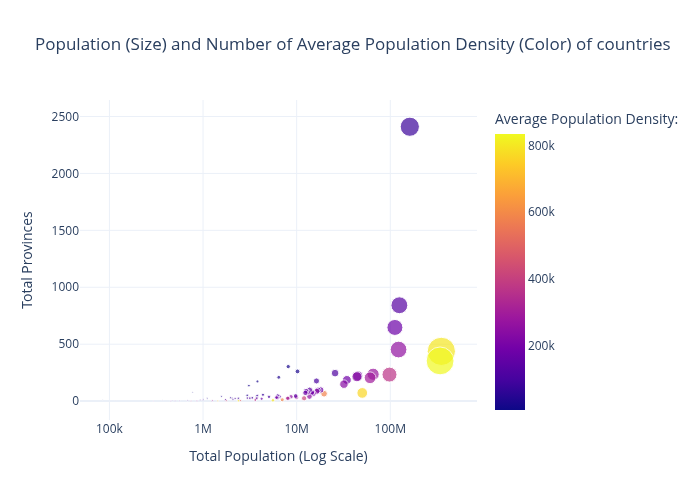

In [94]:
query_population = """
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.provinces_count) AS total_provinces,
    SUM(s.population) AS total_population,
    ROUND(AVG(s.population_density))::INT AS avg_population_density
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
ORDER BY total_population DESC;
"""

df_country = pd.read_sql(query_population, engine)

fig_bubble = px.scatter(
    df_country.head(84),
    x="total_population",
    y="total_provinces",
    size="total_population",
    color="avg_population_density",
    hover_name="country_name",
    log_x=True,
    title="Population (Size) and Number of Average Population Density (Color) of countries",
    labels={
        "total_population": "Total Population (Log Scale)",
        "total_provinces": "Total Provinces",
        "avg_population_density": "Average Population Density: "
    },
    template="plotly_white"
)
fig_bubble.show()

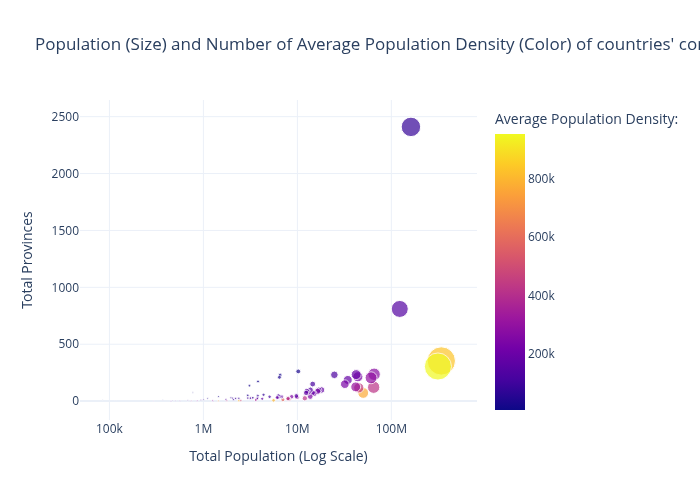

In [95]:
query_core_population = """
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.provinces_count) AS total_provinces,
    SUM(s.population) AS total_population,
    ROUND(AVG(s.population_density))::INT AS avg_population_density
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE state_status = 'Core'
GROUP BY c.country_name, c.country_tag
ORDER BY total_population DESC;
"""

df_core_pop = pd.read_sql(query_core_population, engine)

fig_bubble = px.scatter(
    df_core_pop.head(84),
    x="total_population",
    y="total_provinces",
    size="total_population",
    color="avg_population_density",
    hover_name="country_name",
    log_x=True,
    title="Population (Size) and Number of Average Population Density (Color) of countries' cores",
    labels={
        "total_population": "Total Population (Log Scale)",
        "total_provinces": "Total Provinces",
        "avg_population_density": "Average Population Density: "
    },
    template="plotly_white"
)
fig_bubble.show()

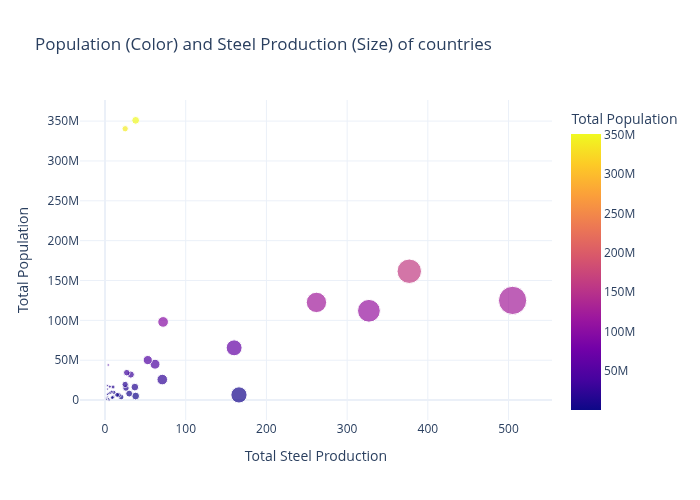

In [96]:
query_steel="""
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.base_steel) AS total_steel,
    SUM(s.population) AS total_population
FROM fact_state_1_14_5 s 
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
HAVING SUM(s.base_steel) > 0
ORDER BY total_steel DESC;
"""
df_steel = pd.read_sql(query_steel, engine)

fig_bubble = px.scatter(
    df_steel.head(84),
    x="total_steel",
    y="total_population",
    size="total_steel",
    color="total_population",
    hover_name="country_name",
    title="Population (Color) and Steel Production (Size) of countries",
    labels={
        "total_steel": "Total Steel Production",
        "total_population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()


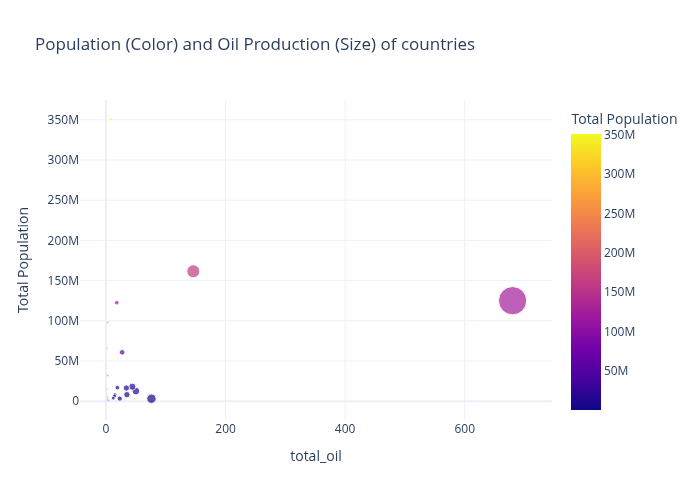

In [97]:
query_oil="""
SELECT 
    c.country_name,
    c.country_tag,
    SUM(s.base_oil) AS total_oil,
    SUM(s.population) AS total_population
FROM fact_state_1_14_5 s 
JOIN dim_country c ON s.owner_tag = c.country_tag
GROUP BY c.country_name, c.country_tag
HAVING SUM(s.base_oil) > 0
ORDER BY total_oil DESC;
"""

df_oil = pd.read_sql(query_oil, engine)

fig_bubble = px.scatter(
    df_oil.head(84),
    x="total_oil",
    y="total_population",
    size="total_oil",
    color="total_population",
    hover_name="country_name",
    title="Population (Color) and Oil Production (Size) of countries",
    labels={
        "total_steel": "Total Oil Production",
        "total_population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()

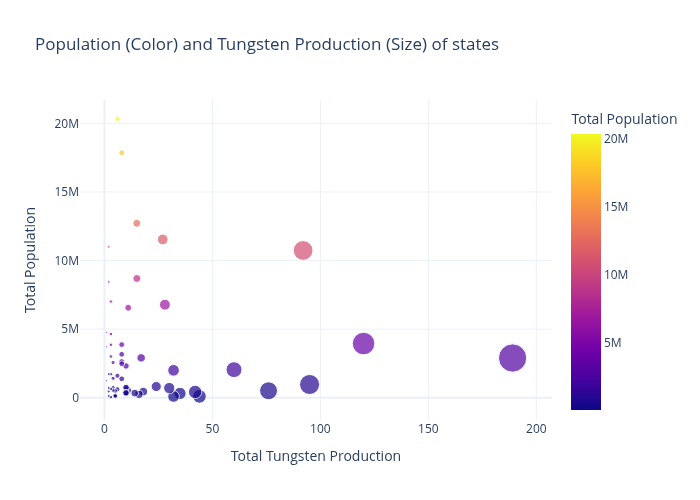

In [98]:
query_top_tungsten_states = """
SELECT 
    s.state_name,
    c.country_name AS owner_country,
    s.population, 
    s.base_tungsten
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE s.base_tungsten > 0
ORDER BY s.base_tungsten DESC;
"""

df_state_tungsten = pd.read_sql(query_top_tungsten_states, engine)
fig_bubble = px.scatter(
    df_state_tungsten.head(969),
    x="base_tungsten",
    y="population",
    size="base_tungsten",
    color="population",
    hover_name="state_name",
    hover_data={"owner_country": True, "base_tungsten": True, "population": True},
    title="Population (Color) and Tungsten Production (Size) of states",
    labels={
        "owner_country": "Owner Country",
        "base_tungsten": "Total Tungsten Production",
        "population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()

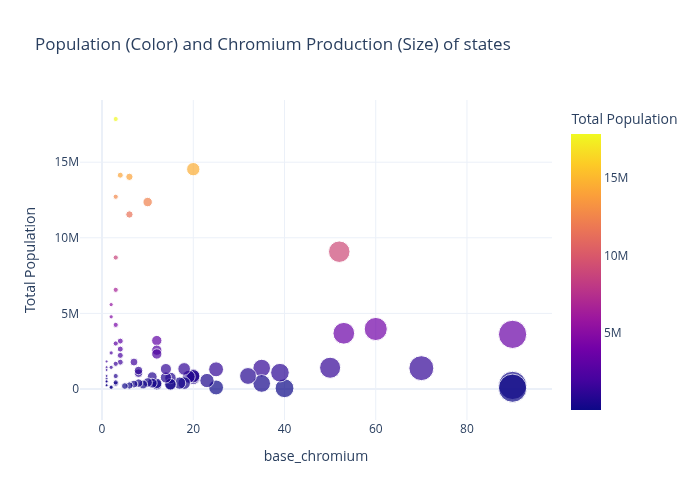

In [99]:
query_top_chromium_states = """
SELECT 
    s.state_name,
    c.country_name AS owner_country,
    s.population,
    s.base_chromium 
FROM fact_state_1_14_5 s
JOIN dim_country c ON s.owner_tag = c.country_tag
WHERE s.base_chromium > 0
ORDER BY s.base_chromium DESC;
"""

df_state_chromium = pd.read_sql(query_top_chromium_states, engine)
fig_bubble = px.scatter(
    df_state_chromium.head(969),
    x="base_chromium",
    y="population",
    size="base_chromium",
    color="population",
    hover_name="state_name",
    hover_data={"owner_country": True, "base_chromium": True, "population": True},
    title="Population (Color) and Chromium Production (Size) of states",
    labels={
        "owner_country": "Owner Country",
        "base_tungsten": "Total Chromium Production",
        "population": "Total Population"
    },
    template="plotly_white"
)
fig_bubble.show()